### Feature Engineering: Encoding, Scaling, and Transformations

This lab follows your Week 7 slides: encoding categorical features, scaling, binning, and logarithmic transformations.

We will use two classifiers: logistic regression and KNN.


All datasets are created in Python or loaded from scikit-learn. No external CSV files are required.

In [ ]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer

#### Part 1 — Encoding categorical features

We will create a small employee dataset (Adult Income dataset). The goal is to predict whether someone earns more than $50,000 annually.

In [ ]:
data = pd.DataFrame({
    "age": [39, 50, 38, 28, 52, 34, 45, 23, 41, 31, 56, 26],

    "workclass": [
        "State-gov", "Self-employed", "Private", "Private",
        "Self-employed", "Private", "State-gov", "Private",
        "Private", "State-gov", "Self-employed", "Private"
    ],

    "education": [
        "Bachelors", "Bachelors", "HS-grad", "Bachelors",
        "HS-grad", "Masters", "Bachelors", "HS-grad",
        "Masters", "Bachelors", "Masters", "HS-grad"
    ],

    "gender": [
        "Male", "Male", "Male", "Female",
        "Male", "Female", "Female", "Male",
        "Female", "Male", "Female", "Female"
    ],

    "hours-per-week": [40, 13, 40, 40, 45, 50, 42, 25, 55, 37, 48, 30],

    "occupation": [
        "Adm-clerical", "Exec-managerial", "Handlers-cleaners",
        "Prof-specialty", "Exec-managerial", "Prof-specialty",
        "Adm-clerical", "Handlers-cleaners", "Exec-managerial",
        "Adm-clerical", "Prof-specialty", "Handlers-cleaners"
    ],

    "income": [
        "<=50K", ">50K", "<=50K", "<=50K",
        ">50K", ">50K", ">50K", "<=50K",
        ">50K", "<=50K", ">50K", "<=50K"
    ]
})

data.head()



,age,workclass,education,gender,hours-per-week,occupation,income
0,39,State-gov,Bachelors,Male,40,Adm-clerical,<=50K
1,50,Self-employed,Bachelors,Male,13,Exec-managerial,>50K
2,38,Private,HS-grad,Male,40,Handlers-cleaners,<=50K
3,28,Private,Bachelors,Female,40,Prof-specialty,<=50K
4,52,Self-employed,HS-grad,Male,45,Exec-managerial,>50K


In [ ]:
# Examine the types of variables
print(data.dtypes)

# Count each category in workclass
print(data["workclass"].value_counts())

age                int64
workclass         object
education         object
gender            object
hours-per-week     int64
occupation        object
income            object
dtype: object
workclass
Private          6
State-gov        3
Self-employed    3
Name: count, dtype: int64


#### One-hot encoding with pandas

pd.get_dummies() converts categorical features into separate 0/1 columns.

In [ ]:
# Separate predictors and target
X = data.drop(columns="income")
y = data["income"]

# One-hot encode categorical variables
X_dummies = pd.get_dummies(X, dtype=int)


X_dummies.head()
#What happened to the number of features?

,age,hours-per-week,workclass_Private,workclass_Self-employed,workclass_State-gov,education_Bachelors,education_HS-grad,education_Masters,gender_Female,gender_Male,occupation_Adm-clerical,occupation_Exec-managerial,occupation_Handlers-cleaners,occupation_Prof-specialty
0,39,40,0,0,1,1,0,0,0,1,1,0,0,0
1,50,13,0,1,0,1,0,0,0,1,0,1,0,0
2,38,40,1,0,0,0,1,0,0,1,0,0,1,0
3,28,40,1,0,0,1,0,0,1,0,0,0,0,1
4,52,45,0,1,0,0,1,0,0,1,0,1,0,0


###OneHotEncoder: Fit on training data, transform test data

Unlike pd.get_dummies(), OneHotEncoder learns the categories from training data and applies the same representation to new observations.

In [ ]:
work_train = pd.DataFrame({
    "workclass": ["Private", "State-gov", "Self-employed", "Private"]
})

work_test = pd.DataFrame({
    "workclass": ["Private", "Private"]
})

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn categories from training data
encoder.fit(work_train)

print("Categories learned:", encoder.categories_[0])

# Transform training data
train_encoded = pd.DataFrame(
    encoder.transform(work_train),
    columns=encoder.get_feature_names_out()
)

# Transform test data using the SAME encoder
test_encoded = pd.DataFrame(
    encoder.transform(work_test),
    columns=encoder.get_feature_names_out()
)

display(train_encoded)
display(test_encoded)

Categories learned: ['Private' 'Self-employed' 'State-gov']


,workclass_Private,workclass_Self-employed,workclass_State-gov
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,0.0
3,1.0,0.0,0.0


,workclass_Private,workclass_Self-employed,workclass_State-gov
0,1.0,0.0,0.0
1,1.0,0.0,0.0


#### What happens with a category that never appeared during training?

In [ ]:
# New category not encountered during training
new_category = pd.DataFrame({
    "workclass": ["Unpaid"]
})

# Apply the encoder learned from training data
new_encoded = encoder.transform(new_category)

display(pd.DataFrame(
    new_encoded,
    columns=encoder.get_feature_names_out()
))

,workclass_Private,workclass_Self-employed,workclass_State-gov
0,0.0,0.0,0.0


Because handle_unknown="ignore" was specified, the new category is represented by zeros rather than producing an error.  

It prevents errors when new categories appear in the test data, but it does not teach the model what those new categories mean.
We should monitor unknown categories and update the model when necessary.

### If you want to encode and scale at the same time, use ColumnTransformer

ColumnTransformer: Combining encoding and scaling.

Our employee dataset contains both numerical and categorical predictors. Let us say that we wanted to:
- Standardize age and hours-per-week.
- One-hot encode workclass, education, gender, and occupation.
- Train logistic regression using the transformed data.

ColumnTransformer allows different preprocessing operations to be applied to different columns.

In [ ]:
numeric_features = ["age", "hours-per-week"]

categorical_features = [
    "workclass", "education", "gender", "occupation"
]


# Build preprocessing steps
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Combine preprocessing with logistic regression
income_pipe = make_pipeline(
    preprocess,
    LogisticRegression(max_iter=2000)
)

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0
)

# Fit preprocessing and model
income_pipe.fit(X_train, y_train)

# Evaluate
print("Test accuracy:", income_pipe.score(X_test, y_test))

Test accuracy: 1.0


This tiny dataset demonstrates the workflow only. Its test accuracy is not a reliable estimate of real-world income prediction performance.

### Part 2 — Scaling features


In [ ]:
#KNN without scaling

# Load dataset
cancer = load_breast_cancer(as_frame=True)

X_cancer = cancer.data
y_cancer = cancer.target

print("Dataset shape:", X_cancer.shape)

# Compare two features with very different ranges
display(
    X_cancer[["mean area", "mean smoothness"]]
    .agg(["min", "max"])
)

Dataset shape: (569, 30)


,mean area,mean smoothness
min,143.5,0.05263
max,2501.0,0.16340


In [ ]:
# Training and test split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.25,
    stratify=y_cancer,
    random_state=4
)

# KNN using original features
knn_raw = KNeighborsClassifier(n_neighbors=5)

knn_raw.fit(Xc_train, yc_train)

print("KNN without scaling:")
print(knn_raw.score(Xc_test, yc_test))

KNN without scaling:
0.9230769230769231


In [ ]:
#KNN with scaling

# Scaling + KNN in one pipeline
knn_scaled = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_scaled.fit(Xc_train, yc_train)

print("KNN with scaling:")
print(knn_scaled.score(Xc_test, yc_test))

KNN with scaling:
0.972027972027972


Compare using 5-fold cross-validation

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=4
)

# KNN without scaling
raw_cv = cross_val_score(
    KNeighborsClassifier(n_neighbors=5),
    Xc_train,
    yc_train,
    cv=cv,
    scoring="accuracy"
)

# KNN with scaling
scaled_cv = cross_val_score(
    make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    Xc_train,
    yc_train,
    cv=cv,
    scoring="accuracy"
)

print("Unscaled CV scores:", raw_cv)
print("Mean:", raw_cv.mean())

print("Scaled CV scores:", scaled_cv)
print("Mean:", scaled_cv.mean())

Unscaled CV scores: [0.90697674 0.90588235 0.91764706 0.89411765 1.        ]
Mean: 0.9249247606019152
Scaled CV scores: [0.91860465 0.97647059 0.97647059 0.96470588 0.94117647]
Mean: 0.9554856361149111


The scaler is inside the pipeline so it is fitted separately on each training fold, avoiding data leakage.

### Part 3 — Transforming features

Binning continuous variables: Binning divides a continuous variable into intervals.

We will create six intervals and represent them using one-hot encoding.

In [ ]:
X_bins = pd.DataFrame({
    "x": [-2.8, -1.7, -0.8, 0.3, 1.39, 2.5]
})

binner = KBinsDiscretizer(
    n_bins=6,
    encode="onehot-dense",
    strategy="uniform"
)

encoded_bins = binner.fit_transform(X_bins)


print("Bin boundaries:")
print(binner.bin_edges_[0])


# Display
bins_df = pd.DataFrame(
    encoded_bins.astype(int),
    columns=[f"bin_{i+1}" for i in range(encoded_bins.shape[1])]
)

# Add original values as the first column
bins_df.insert(0, "Original x", X_bins["x"])

display(bins_df)

Bin boundaries:
[-2.8  -1.74 -0.68  0.38  1.44  2.5 ]


,Original x,bin_1,bin_2,bin_3,bin_4,bin_5
0,-2.80,1,0,0,0,0
1,-1.00,0,1,0,0,0
2,-0.80,0,1,0,0,0
3,0.30,0,0,1,0,0
4,1.39,0,0,0,1,0
5,2.50,0,0,0,0,1


Strategy:

- "uniform"	Each bin has the same width
- "quantile"	Each bin has approximately the same number of observations
- "kmeans"	Uses K-means clustering to find bin boundaries based on the distribution of values

### Log Transformation

We will use the California Housing dataset from scikit-learn. We'll examine MedInc (median income), a numerical feature that is right-skewed. It is measured in $10,000s.

We would apply a log transformation to median income because the feature is right-skewed: most neighborhoods have low to moderate incomes, while a smaller number have very high incomes.

The log transformation compresses high income values more than low income values, reducing the influence of extreme values on the feature's scale.

**Why might this help machine learning?**

For example, an increase in median income from 20,000 to 40,000 may have a different relationship with house prices than an increase from 120,000  to 140,000. A log transformation allows a linear model to represent a relationship in which the effect of income changes as income increases.

We are not transforming income just to make its distribution look more symmetrical. We do it because the transformed feature might better represent its **relationship** with house prices.

Log transformation can help a linear model capture nonlinear relationships and reduce the influence of very large feature values.


We must use cross-validation to determine whether it actually improves predictions.

In [ ]:
from sklearn.datasets import fetch_california_housing

# Load California housing data
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
income = df["MedInc"]

# Apply log transformation
income_log = np.log1p(income)

# Compare
comparison = pd.DataFrame({
    "Original Income": income,
    "Log(Income + 1)": income_log
})

comparison.head(10)

,Original Income,Log(Income + 1)
0,8.3252,2.232720
1,8.3014,2.230165
2,7.2574,2.111110
3,5.6431,1.893579
4,3.8462,1.578195
5,4.0368,1.616771
6,3.6591,1.538822
7,3.1200,1.415853
8,2.0804,1.125059
9,3.6912,1.545688


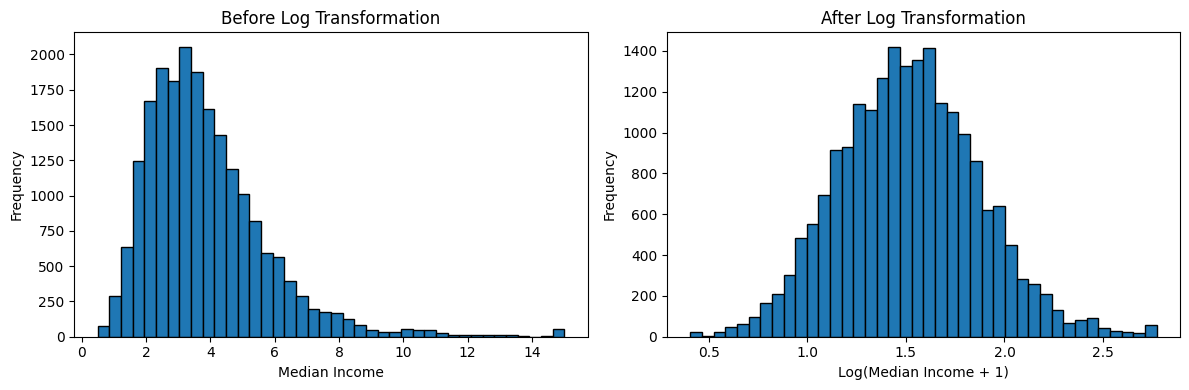

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Before transformation
axes[0].hist(income, bins=40, edgecolor="black")
axes[0].set_title("Before Log Transformation")
axes[0].set_xlabel("Median Income")
axes[0].set_ylabel("Frequency")

# After transformation
axes[1].hist(income_log, bins=40, edgecolor="black")
axes[1].set_title("After Log Transformation")
axes[1].set_xlabel("Log(Median Income + 1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()